In [1]:
print('hello world')

hello world


In [2]:
#hi

## 🚀 Advanced YOLOv8 Character Detection Pipeline
### Hybrid OCR + YOLO Training with Data Augmentation

#### Pipeline Overview:
1. **Data Analysis & Exploration** - Analyze 236 annotated images
2. **COCO Dataset Conversion** - Convert JSON annotations to COCO format
3. **Class Distribution Analysis** - Analyze 36 character classes
4. **Data Augmentation** - Rotation with coordinate adjustment
5. **YOLOv8 Training** - Character-level detection training
6. **OCR Integration** - Hybrid OCR+YOLO approach
7. **Model Evaluation** - Comprehensive metrics and visualization

**Dataset**: 236 Serial Number Images (36 Character Classes)  
**Environment**: Windows + CUDA + PyTorch


### 📦 1. Environment Setup & Imports

In [6]:
# Core libraries
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.transforms.functional import rotate

# Computer vision & ML
import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import albumentations as A
from albumentations.pytorch import ToTensorV2

# YOLO & Object Detection
from ultralytics import YOLO
import ultralytics

# OCR Integration
import easyocr
import pytesseract

# Data handling
import json
import pandas as pd
import numpy as np
from pathlib import Path
import shutil
import yaml
from collections import Counter, defaultdict
import random
from datetime import datetime
import pickle
import re
import math

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from matplotlib.patches import Rectangle
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Metrics & Evaluation
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("✅ All libraries imported successfully!")
print(f"🎯 PyTorch version: {torch.__version__}")
print(f"🎯 CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"🎯 GPU: {torch.cuda.get_device_name(0)}")
print(f"🎯 Ultralytics version: {ultralytics.__version__}")

✅ All libraries imported successfully!
🎯 PyTorch version: 2.5.1+cu121
🎯 CUDA available: True
🎯 GPU: NVIDIA GeForce GTX 1650
🎯 Ultralytics version: 8.3.163


### ⚙️ 2. Configuration & Global Variables

In [7]:
# =============================================================================
# CONFIGURATION SETTINGS
# =============================================================================

class Config:
    """Configuration class for the entire pipeline"""
    
    # Paths
    INPUT_IMAGES_DIR = Path("annotations/input_images")
    JSON_ANNOTATIONS_DIR = Path("annotations/json annotations")
    VISUAL_ANNOTATIONS_DIR = Path("annotations/visual_annotations")
    
    # Output directories
    OUTPUT_DIR = Path("yolo_training_output")
    DATASET_DIR = OUTPUT_DIR / "dataset"
    AUGMENTED_DIR = OUTPUT_DIR / "augmented_data"
    MODELS_DIR = OUTPUT_DIR / "models"
    RESULTS_DIR = OUTPUT_DIR / "results"
    VISUALIZATIONS_DIR = OUTPUT_DIR / "visualizations"
    
    # Character classes mapping (36 classes)
    CHAR_TO_ID = {
        'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7,
        'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 
        'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21,
        'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 
        '0': 26, '1': 27, '2': 28, '3': 29, '4': 30, '5': 31, 
        '6': 32, '7': 33, '8': 34, '9': 35
    }
    
    ID_TO_CHAR = {v: k for k, v in CHAR_TO_ID.items()}
    
    # Serial number patterns (3 formats)
    SERIAL_PATTERNS = {
        'Format1_AAnnnnA': r'^[A-Z]{2}\d{4}[A-Z]$',  # AAnnnnA (e.g., FD8764S)
        'Format2_AAnnnAn': r'^[A-Z]{2}\d{3}[A-Z]\d$', # AAnnnAn (e.g., GF887E1) 
        'Format3_AAAnnnA': r'^[A-Z]{3}\d{3}[A-Z]$'   # AAAnnnA (e.g., JFH772B)
    }
    
    # Training parameters
    TRAIN_SPLIT = 0.8
    VAL_SPLIT = 0.15
    TEST_SPLIT = 0.05
    
    # Augmentation settings
    ROTATION_ANGLES = [-15, -10, -5, 0, 5, 10, 15]  # degrees
    BRIGHTNESS_RANGE = (0.7, 1.3)
    CONTRAST_RANGE = (0.8, 1.2)
    
    # YOLO training parameters
    YOLO_MODEL_SIZE = 'yolov8n.pt'  # nano, small, medium, large, x
    EPOCHS = 100
    BATCH_SIZE = 16
    IMAGE_SIZE = 640
    PATIENCE = 15
    
    # OCR settings
    OCR_CONFIDENCE_THRESHOLD = 0.5
    ENSEMBLE_WEIGHT_YOLO = 0.7
    ENSEMBLE_WEIGHT_OCR = 0.3

# Create output directories
for dir_path in [Config.OUTPUT_DIR, Config.DATASET_DIR, Config.AUGMENTED_DIR, 
                 Config.MODELS_DIR, Config.RESULTS_DIR, Config.VISUALIZATIONS_DIR]:
    dir_path.mkdir(parents=True, exist_ok=True)

print("✅ Configuration initialized")
print(f"📊 Total character classes: {len(Config.CHAR_TO_ID)}")
print(f"📊 Serial number formats: {len(Config.SERIAL_PATTERNS)}")
print(f"📁 Output directory: {Config.OUTPUT_DIR.absolute()}")


✅ Configuration initialized
📊 Total character classes: 36
📊 Serial number formats: 3
📁 Output directory: c:\Users\mynam\Downloads\Fuel bundle serial number detection\yolo_training_output


### 📊 3. Data Analysis & Exploration

🔍 Loading annotation files...
📁 Found 236 annotation files
✅ Loaded 236 annotations successfully
📊 COMPREHENSIVE DATA ANALYSIS REPORT
📁 Total Images: 236
🔤 Total Characters: 1649
📊 Average Characters per Image: 6.99
📏 Image Dimensions Range: 1590x1590 to 2448x3264

📋 Serial Number Pattern Distribution:
   Format3_AAAnnnA: 206 (87.3%)
   Format2_AAnnnAn: 30 (12.7%)

🔤 Character Class Distribution:
   4 (ID:30):  92 ( 5.6%)
   3 (ID:29):  89 ( 5.4%)
   7 (ID:33):  83 ( 5.0%)
   8 (ID:34):  81 ( 4.9%)
   9 (ID:35):  71 ( 4.3%)
   0 (ID:26):  70 ( 4.2%)
   5 (ID:31):  68 ( 4.1%)
   1 (ID:27):  66 ( 4.0%)
   2 (ID:28):  62 ( 3.8%)
   6 (ID:32):  56 ( 3.4%)
   O (ID:14):  45 ( 2.7%)
   P (ID:15):  42 ( 2.5%)
   K (ID:10):  42 ( 2.5%)
   U (ID:20):  41 ( 2.5%)
   E (ID: 4):  40 ( 2.4%)
   M (ID:12):  40 ( 2.4%)
   N (ID:13):  39 ( 2.4%)
   J (ID: 9):  39 ( 2.4%)
   C (ID: 2):  37 ( 2.2%)
   B (ID: 1):  36 ( 2.2%)
   Q (ID:16):  36 ( 2.2%)
   L (ID:11):  35 ( 2.1%)
   Z (ID:25):  35 ( 2.1%)
  

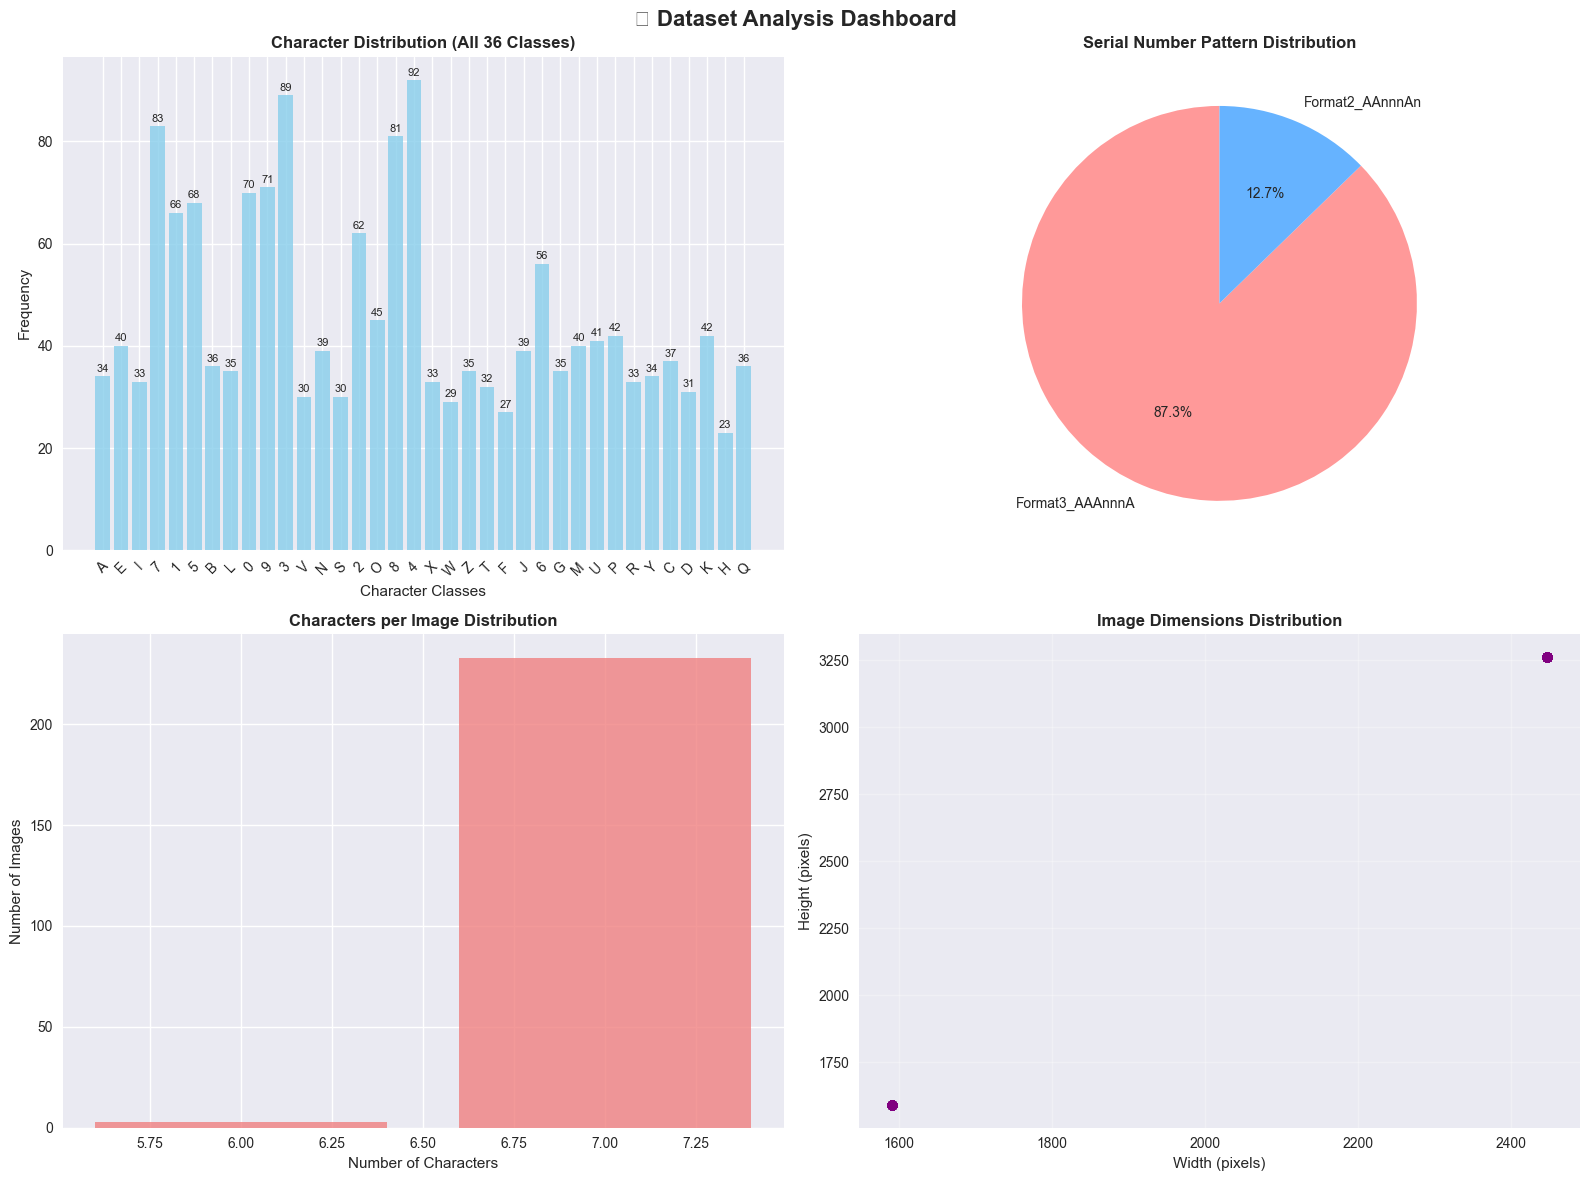

✅ Data analysis completed and saved to CSV


In [11]:
class DataAnalyzer:
    """Comprehensive data analysis for the annotation dataset"""
    
    def __init__(self):
        self.annotations_data = []
        self.character_distribution = Counter()
        self.pattern_distribution = Counter()
        self.image_stats = {}
        
    def load_all_annotations(self):
        """Load and analyze all JSON annotation files"""
        print("🔍 Loading annotation files...")
        
        json_files = list(Config.JSON_ANNOTATIONS_DIR.glob("*.json"))
        print(f"📁 Found {len(json_files)} annotation files")
        
        for json_file in json_files:
            try:
                with open(json_file, 'r') as f:
                    data = json.load(f)
                    
                # Extract image info
                filename = data['image_info']['filename']
                width = data['image_info']['width']
                height = data['image_info']['height']
                
                # Extract character annotations
                char_annotations = []
                if 'character_annotations' in data:
                    char_annotations = data['character_annotations']
                elif 'validated_words' in data and len(data['validated_words']) > 0:
                    # Fallback to validated_words character breakdown
                    for word_data in data['validated_words']:
                        if 'character_annotations' in word_data:
                            char_annotations.extend(word_data['character_annotations'])
                
                # Count characters
                for char_data in char_annotations:
                    char = char_data.get('text', '').upper()
                    if char in Config.CHAR_TO_ID:
                        self.character_distribution[char] += 1
                
                # Determine pattern
                serial_number = filename.split('.')[0]  # Remove extension
                pattern = self._classify_pattern(serial_number)
                self.pattern_distribution[pattern] += 1
                
                # Store data
                annotation_entry = {
                    'filename': filename,
                    'json_file': json_file.name,
                    'width': width,
                    'height': height,
                    'character_count': len(char_annotations),
                    'characters': [c.get('text', '').upper() for c in char_annotations],
                    'pattern': pattern,
                    'serial_number': serial_number
                }
                
                self.annotations_data.append(annotation_entry)
                
            except Exception as e:
                print(f"⚠️ Error loading {json_file.name}: {e}")
        
        print(f"✅ Loaded {len(self.annotations_data)} annotations successfully")
        return self.annotations_data
    
    def _classify_pattern(self, serial_number):
        """Classify serial number into one of the 3 patterns"""
        for pattern_name, regex in Config.SERIAL_PATTERNS.items():
            if re.match(regex, serial_number):
                return pattern_name
        return "Unknown"
    
    def generate_comprehensive_report(self):
        """Generate comprehensive data analysis report"""
        if not self.annotations_data:
            self.load_all_annotations()
        
        df = pd.DataFrame(self.annotations_data)
        
        print("=" * 70)
        print("📊 COMPREHENSIVE DATA ANALYSIS REPORT")
        print("=" * 70)
        
        # Basic statistics
        total_images = len(df)
        total_characters = sum(df['character_count'])
        avg_chars_per_image = total_characters / total_images if total_images > 0 else 0
        
        print(f"📁 Total Images: {total_images}")
        print(f"🔤 Total Characters: {total_characters}")
        print(f"📊 Average Characters per Image: {avg_chars_per_image:.2f}")
        print(f"📏 Image Dimensions Range: {df['width'].min()}x{df['height'].min()} to {df['width'].max()}x{df['height'].max()}")
        
        # Pattern distribution
        print(f"\n📋 Serial Number Pattern Distribution:")
        for pattern, count in self.pattern_distribution.most_common():
            percentage = (count / total_images) * 100
            print(f"   {pattern}: {count} ({percentage:.1f}%)")
        
        # Character distribution
        print(f"\n🔤 Character Class Distribution:")
        for char, count in self.character_distribution.most_common():
            class_id = Config.CHAR_TO_ID.get(char, -1)
            percentage = (count / total_characters) * 100
            print(f"   {char} (ID:{class_id:2d}): {count:3d} ({percentage:4.1f}%)")
        
        return df
    
    def visualize_distributions(self):
        """Create comprehensive visualizations"""
        if not self.annotations_data:
            self.load_all_annotations()
        
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        fig.suptitle('📊 Dataset Analysis Dashboard', fontsize=16, fontweight='bold')
        
        # 1. Character distribution
        chars = list(self.character_distribution.keys())
        counts = list(self.character_distribution.values())
        
        ax1 = axes[0, 0]
        bars = ax1.bar(chars, counts, color='skyblue', alpha=0.8)
        ax1.set_title('Character Distribution (All 36 Classes)', fontweight='bold')
        ax1.set_xlabel('Character Classes')
        ax1.set_ylabel('Frequency')
        ax1.tick_params(axis='x', rotation=45)
        
        # Add value labels on bars
        for bar in bars:
            height = bar.get_height()
            ax1.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{int(height)}',
                    ha='center', va='bottom', fontsize=8)
        
        # 2. Pattern distribution
        patterns = list(self.pattern_distribution.keys())
        pattern_counts = list(self.pattern_distribution.values())
        
        ax2 = axes[0, 1]
        colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']
        wedges, texts, autotexts = ax2.pie(pattern_counts, labels=patterns, autopct='%1.1f%%',
                                          colors=colors, startangle=90)
        ax2.set_title('Serial Number Pattern Distribution', fontweight='bold')
        
        # 3. Characters per image distribution
        df = pd.DataFrame(self.annotations_data)
        char_counts = df['character_count'].value_counts().sort_index()
        
        ax3 = axes[1, 0]
        ax3.bar(char_counts.index, char_counts.values, color='lightcoral', alpha=0.8)
        ax3.set_title('Characters per Image Distribution', fontweight='bold')
        ax3.set_xlabel('Number of Characters')
        ax3.set_ylabel('Number of Images')
        
        # 4. Image dimension distribution
        ax4 = axes[1, 1]
        ax4.scatter(df['width'], df['height'], alpha=0.6, c='purple')
        ax4.set_title('Image Dimensions Distribution', fontweight='bold')
        ax4.set_xlabel('Width (pixels)')
        ax4.set_ylabel('Height (pixels)')
        ax4.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.savefig(Config.VISUALIZATIONS_DIR / 'dataset_analysis.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        return fig

# Initialize and run analysis
analyzer = DataAnalyzer()
df_annotations = analyzer.generate_comprehensive_report()
analyzer.visualize_distributions()
# Save analysis results to CSV
df_annotations.to_csv(Config.VISUALIZATIONS_DIR / 'annotations_analysis.csv', index=False)
print("✅ Data analysis completed and saved to CSV")

### 🔄 4. COCO Dataset Conversion & YOLO Format


In [ ]:
class YOLODatasetConverter:
    """Convert annotation dataset to YOLO format with train/val/test splits"""
    
    def __init__(self):
        self.train_images = []
        self.val_images = []
        self.test_images = []
        
    def create_yolo_dataset_structure(self):
        """Create YOLO dataset directory structure"""
        print("🏗️ Creating YOLO dataset structure...")
        
        # Create directories
        for split in ['train', 'val', 'test']:
            (Config.DATASET_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
            (Config.DATASET_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)
        
        print(f"✅ Dataset structure created at {Config.DATASET_DIR}")
    
    def split_dataset(self, annotations_df):
        """Smart dataset splitting based on patterns"""
        print("📊 Splitting dataset strategically...")
        
        # Group by pattern for stratified split
        pattern_groups = annotations_df.groupby('pattern')
        
        train_list, val_list, test_list = [], [], []
        
        for pattern, group in pattern_groups:
            # Shuffle within each pattern
            group_shuffled = group.sample(frac=1, random_state=42)
            n = len(group_shuffled)
            
            # Calculate splits
            train_size = int(n * Config.TRAIN_SPLIT)
            val_size = int(n * Config.VAL_SPLIT)
            
            # Split the group
            train_group = group_shuffled.iloc[:train_size]
            val_group = group_shuffled.iloc[train_size:train_size + val_size]
            test_group = group_shuffled.iloc[train_size + val_size:]
            
            train_list.append(train_group)
            val_list.append(val_group)
            if len(test_group) > 0:
                test_list.append(test_group)
            
            print(f"   {pattern}: Train={len(train_group)}, Val={len(val_group)}, Test={len(test_group)}")
        
        # Combine all splits
        train_df = pd.concat(train_list, ignore_index=True) if train_list else pd.DataFrame()
        val_df = pd.concat(val_list, ignore_index=True) if val_list else pd.DataFrame()
        test_df = pd.concat(test_list, ignore_index=True) if test_list else pd.DataFrame()
        
        print(f"📊 Final split: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")
        
        return train_df, val_df, test_df
    
    def convert_annotations_to_yolo(self, split_name, df_split):
        """Convert JSON annotations to YOLO format"""
        print(f"🔄 Converting {split_name} annotations to YOLO format...")
        
        converted_count = 0
        
        for _, row in df_split.iterrows():
            try:
                # Load original JSON annotation
                json_path = Config.JSON_ANNOTATIONS_DIR / row['json_file']
                with open(json_path, 'r') as f:
                    data = json.load(f)
                
                # Get image info
                image_width = data['image_info']['width']
                image_height = data['image_info']['height']
                filename = row['filename']
                
                # Copy image to dataset directory
                src_image = Config.INPUT_IMAGES_DIR / filename
                dst_image = Config.DATASET_DIR / split_name / 'images' / filename
                
                if src_image.exists():
                    shutil.copy2(src_image, dst_image)
                else:
                    print(f"⚠️ Warning: Image not found: {src_image}")
                    continue
                
                # Extract character annotations
                char_annotations = []
                if 'character_annotations' in data:
                    char_annotations = data['character_annotations']
                elif 'validated_words' in data and len(data['validated_words']) > 0:
                    # Extract from validated_words if available
                    for word_data in data['validated_words']:
                        if 'character_annotations' in word_data:
                            char_annotations.extend(word_data['character_annotations'])
                
                # Create YOLO label file
                label_path = Config.DATASET_DIR / split_name / 'labels' / f"{Path(filename).stem}.txt"
                
                with open(label_path, 'w') as f:
                    for char_data in char_annotations:
                        char = char_data.get('text', '').upper()
                        if char in Config.CHAR_TO_ID:
                            class_id = Config.CHAR_TO_ID[char]
                            
                            # Get bounding box
                            bbox = char_data.get('bbox', [])
                            if len(bbox) == 4:
                                x_min, y_min, x_max, y_max = bbox
                                
                                # Convert to YOLO format (normalized center coordinates)
                                center_x = (x_min + x_max) / 2 / image_width
                                center_y = (y_min + y_max) / 2 / image_height
                                width = (x_max - x_min) / image_width
                                height = (y_max - y_min) / image_height
                                
                                # Ensure values are within [0, 1]
                                center_x = max(0, min(1, center_x))
                                center_y = max(0, min(1, center_y))
                                width = max(0, min(1, width))
                                height = max(0, min(1, height))
                                
                                f.write(f"{class_id} {center_x:.6f} {center_y:.6f} {width:.6f} {height:.6f}\n")
                
                converted_count += 1
                
            except Exception as e:
                print(f"⚠️ Error converting {row['filename']}: {e}")
        
        print(f"✅ Converted {converted_count}/{len(df_split)} {split_name} annotations")
        return converted_count
    
    def create_dataset_yaml(self):
        """Create dataset.yaml for YOLO training"""
        dataset_config = {
            'path': str(Config.DATASET_DIR.absolute()),
            'train': 'train/images',
            'val': 'val/images',
            'test': 'test/images',
            'nc': len(Config.CHAR_TO_ID),  # number of classes
            'names': Config.ID_TO_CHAR
        }
        
        yaml_path = Config.DATASET_DIR / 'dataset.yaml'
        with open(yaml_path, 'w') as f:
            yaml.dump(dataset_config, f, default_flow_style=False)
        
        print(f"✅ Created dataset.yaml at {yaml_path}")
        return yaml_path
    
    def convert_full_dataset(self, annotations_df):
        """Complete dataset conversion pipeline"""
        print("🚀 Starting full dataset conversion...")
        
        # Create directory structure
        self.create_yolo_dataset_structure()
        
        # Split dataset
        train_df, val_df, test_df = self.split_dataset(annotations_df)
        
        # Convert each split
        train_count = self.convert_annotations_to_yolo('train', train_df)
        val_count = self.convert_annotations_to_yolo('val', val_df)
        test_count = self.convert_annotations_to_yolo('test', test_df) if len(test_df) > 0 else 0
        
        # Create dataset.yaml
        yaml_path = self.create_dataset_yaml()
        
        # Summary
        print("=" * 60)
        print("📊 DATASET CONVERSION SUMMARY")
        print("=" * 60)
        print(f"✅ Train: {train_count} images")
        print(f"✅ Validation: {val_count} images") 
        print(f"✅ Test: {test_count} images")
        print(f"📁 Dataset location: {Config.DATASET_DIR}")
        print(f"📄 Configuration: {yaml_path}")
        print("=" * 60)
        
        return {
            'train_count': train_count,
            'val_count': val_count,
            'test_count': test_count,
            'yaml_path': yaml_path
        }

# Convert dataset
converter = YOLODatasetConverter()
conversion_results = converter.convert_full_dataset(df_annotations)
